# Banking Analytics with Hadoop, Hive and Spark

**Colab-ready capstone notebook** · five parts · based on the supplied bank.csv

This project demonstrates Hadoop MapReduce and Hive, Spark EDA, Spark ML classification, Structured Streaming, and data parallelism. The provided telecom notebooks were used only as examples of EDA and ML walkthrough structure; their dataset, results, and conclusions are not reused.

> Data limits: bank.csv has no year, event timestamp, or loan principal. Stream event times are synthetic replay metadata. The balance field is an average yearly balance per client. In the age-band loan exercise, it is a labelled proxy for the unavailable loan principal.

**How to run:** use Runtime → Run all in Colab. The setup cell clones this public repository when it is not already present and installs the pinned PySpark version. Hadoop and Hive execution needs a configured cluster; the notebook locally replays Hadoop mapper/reducer logic and prints the Hive scripts and commands.

## Setup and dataset inspection

In [1]:
from pathlib import Path
import importlib.util
import os
import shutil
import subprocess
import sys
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

REPO_URL = "https://github.com/harshpaul1999-tech/banking-distributed-ml.git"
REPO_DIR = Path.cwd()
if not (REPO_DIR / "data" / "bank.csv").exists():
    REPO_DIR = Path("/content/banking-distributed-ml")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
os.chdir(REPO_DIR)
print("project directory:", REPO_DIR)

# Colab normally has Java already. On a Debian Colab runtime, install Java 17
# only when no Java executable is available.
if shutil.which("java") is None and Path("/etc/debian_version").exists():
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-17-jre-headless"], check=True)
if shutil.which("java") is None:
    raise RuntimeError("Java 17 is required for the local Spark session.")
if not os.environ.get("JAVA_HOME"):
    java_path = Path(shutil.which("java")).resolve()
    for candidate in [java_path.parents[1], Path("/usr/lib/jvm/java-17-openjdk-amd64")]:
        if candidate.exists():
            os.environ["JAVA_HOME"] = str(candidate)
            break
print("JAVA_HOME:", os.environ.get("JAVA_HOME", "runtime default"))

from importlib.metadata import PackageNotFoundError, version
try:
    current_pyspark = version("pyspark")
except PackageNotFoundError:
    current_pyspark = None
if current_pyspark != "3.5.6":
    install_args = [sys.executable, "-m", "pip", "install", "-q"]
    if current_pyspark is not None:
        install_args.append("--force-reinstall")
    install_args.append("pyspark==3.5.6")
    subprocess.run(install_args, check=True)
import pyspark
print("PySpark:", pyspark.__version__)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas>=2.0,<3.0", "matplotlib>=3.7,<4.0", "psutil>=5.9,<8.0"], check=True)
print("PySpark:", pyspark.__version__)

import pandas as pd
source_csv = REPO_DIR / "data" / "bank.csv"
pandas_check = pd.read_csv(source_csv)
print("dataset shape:", pandas_check.shape)
print("columns:", list(pandas_check.columns))
print("subscribed:", int((pandas_check.y == "yes").sum()),
      f"({(pandas_check.y == 'yes').mean():.2%})")
print("missing cells:", int(pandas_check.isna().sum().sum()))
print("duplicate rows:", int(pandas_check.duplicated().sum()))

def run_project_script(*args):
    subprocess.run([sys.executable, *args], cwd=REPO_DIR, check=True)


project directory: PROJECT_ROOT
JAVA_HOME: /opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home


You should consider upgrading via the 'python -m pip install --upgrade pip' command.


PySpark: 3.5.6


dataset shape: (4521, 17)
columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
subscribed: 521 (11.52%)
missing cells: 0
duplicate rows: 0


# Part 1 — Hadoop MapReduce and Hive

The HDFS and Hive commands below are cluster-ready instructions. No HDFS or Hive service is launched by Colab. The local replay runs the same mapper/reducer programs with a local key sort, which lets us inspect their logic without calling it a Hadoop execution.

In [2]:
print((REPO_DIR / "src/hadoop/run_hadoop_examples.sh").read_text())
print()
print("Hive DDL and requested queries:")
print()
print((REPO_DIR / "sql/banking_queries.hql").read_text())

#!/usr/bin/env bash
# Run from the repository root on a Hadoop cluster with Python 3 on worker nodes.
set -euo pipefail

if [[ -z "${HADOOP_HOME:-}" ]]; then
  echo "Set HADOOP_HOME to a Hadoop installation with the streaming JAR." >&2
  exit 2
fi
DATA_PATH="${1:-/user/$USER/banking/input/bank.csv}"
OUTPUT_BASE="${2:-/user/$USER/banking/output}"
RUN_ID="$(date -u +%Y%m%dT%H%M%SZ)"
STREAMING_JAR="$(find "$HADOOP_HOME/share/hadoop/tools/lib" -name 'hadoop-streaming-*.jar' -print -quit)"
HDFS_DATA="/user/$USER/banking/input"

if [[ -z "$STREAMING_JAR" ]]; then
  echo "Could not find the Hadoop Streaming JAR under HADOOP_HOME." >&2
  exit 2
fi
hdfs dfs -mkdir -p "$HDFS_DATA"
hdfs dfs -put -f data/bank.csv "$HDFS_DATA/bank.csv"

run_job() {
  local name="$1" mapper="$2" reducer="$3"
  local output="$OUTPUT_BASE/$RUN_ID/$name"
  hadoop jar "$STREAMING_JAR" \
    -D "mapreduce.job.name=$name" \
    -files "src/hadoop/$mapper,src/hadoop/csv_rows.py,src/hadoop/$reducer" \
    -mapper "python3 $

In [3]:
import subprocess

hadoop_dir = REPO_DIR / "src/hadoop"
csv_text = source_csv.read_text(encoding="utf-8-sig")

jobs = [
    ("average balance by job", "mr_average_balance_mapper.py", "mr_average_balance_reducer.py"),
    ("housing counts by education", "mr_housing_by_education_mapper.py", "mr_count_reducer.py"),
    ("month and subscription counts", "mr_month_subscription_mapper.py", "mr_count_reducer.py"),
    ("average duration by prior outcome", "mr_average_duration_mapper.py", "mr_average_balance_reducer.py"),
    ("age and balance summary", "mr_age_balance_mapper.py", "mr_age_balance_reducer.py"),
]
for label, mapper_name, reducer_name in jobs:
    mapped = subprocess.run([sys.executable, str(hadoop_dir / mapper_name)],
                            input=csv_text, text=True, capture_output=True, check=True).stdout.splitlines()
    # Hadoop's shuffle sorts mapper keys before the reducer sees each key group.
    shuffled = "\n".join(sorted(mapped, key=lambda line: line.split("\t", 1)[0])) + "\n"
    reduced = subprocess.run([sys.executable, str(hadoop_dir / reducer_name)],
                             input=shuffled, text=True, capture_output=True, check=True).stdout
    print(f"\n{label} — local mapper/shuffle/reducer replay")
    print(reduced)



average balance by job — local mapper/shuffle/reducer replay
admin.	1226.74	478
blue-collar	1085.16	946
entrepreneur	1645.12	168
housemaid	2083.80	112
management	1766.93	969
retired	2319.19	230
self-employed	1392.41	183
services	1103.96	417
student	1543.82	84
technician	1331.00	768
unemployed	1089.42	128
unknown	1501.71	38


housing counts by education — local mapper/shuffle/reducer replay
primary|no	295
primary|yes	383
secondary|no	876
secondary|yes	1430
tertiary|no	687
tertiary|yes	663
unknown|no	104
unknown|yes	83




month and subscription counts — local mapper/shuffle/reducer replay
apr|no	237
apr|yes	56
aug|no	554
aug|yes	79
dec|no	11
dec|yes	9
feb|no	184
feb|yes	38
jan|no	132
jan|yes	16
jul|no	645
jul|yes	61
jun|no	476
jun|yes	55
mar|no	28
mar|yes	21
may|no	1305
may|yes	93
nov|no	350
nov|yes	39
oct|no	43
oct|yes	37
sep|no	35
sep|yes	17




average duration by prior outcome — local mapper/shuffle/reducer replay
failure	254.38	490
other	273.83	197
success	338.64	129
unknown	262.10	3705


age and balance summary — local mapper/shuffle/reducer replay
rows=4521	mean_age=41.17	mean_balance=1422.66	pearson_r=0.0838



### Part 1 interpretation

May is the most contacted month in the supplied file, with 1,398 contacts and a 6.65% subscription rate. Age and balance correlation is about 0.0838. The SQL also compares previous campaign outcome with current subscription. Year-over-year contact trends cannot be calculated because there is no year field. Average yearly balance can be compared by education, but the file is not a multi-year time series.

## Part 2 — Spark data processing and EDA

In [4]:
# This script runs the Spark DataFrame inspection and all 12 requested analyses.
run_project_script("src/spark/batch_analytics.py", "--data", "data/bank.csv")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/24 01:06:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/24 01:06:16 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


rows=4521 columns=17
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job        |marital|education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|30 |unemployed |married|primary  |no     |1787   |no     |no  |cellular|19 |oct  |79      |1       |-1   |0       |unknown |no |
|33 |services   |married|secondary|no     |4789   |yes    |yes |cellular|11 |may  |220     |1       |339  |4       |failure |no |
|35 |management |single |tertiary |no     |1350   |yes    |no  |cellular|16 |apr  |185     |1       |330  |1       |failure |no |
|30 |management |married|tertiary |no     |1476   |yes    |yes |unknown |3  |jun  |199     |4       |-1   |0       |unknown |no |
|59 |blue-collar|married|secondary|no     |0      |yes    |no  |unkno

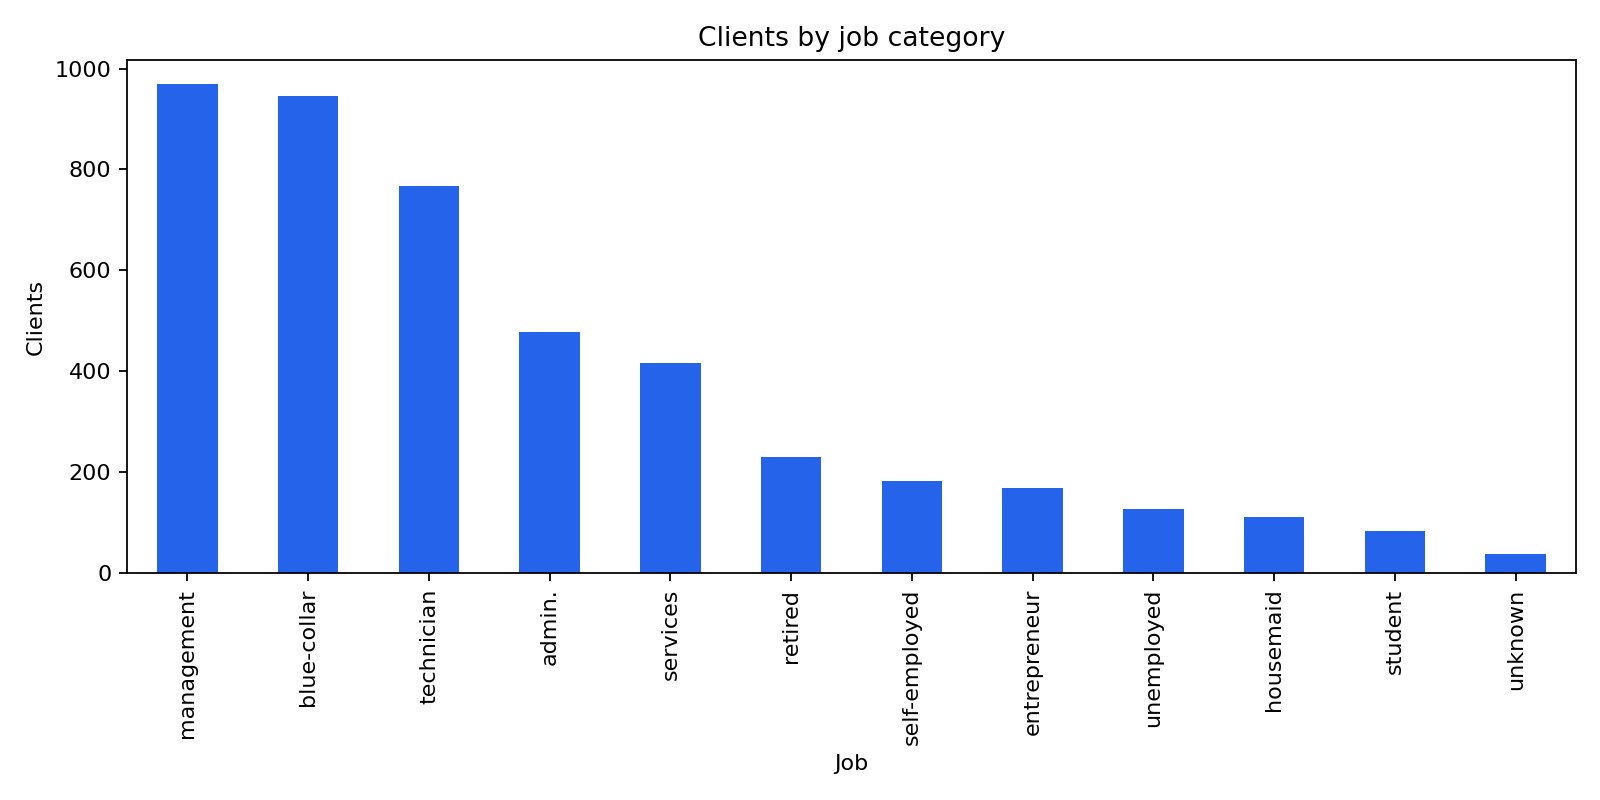

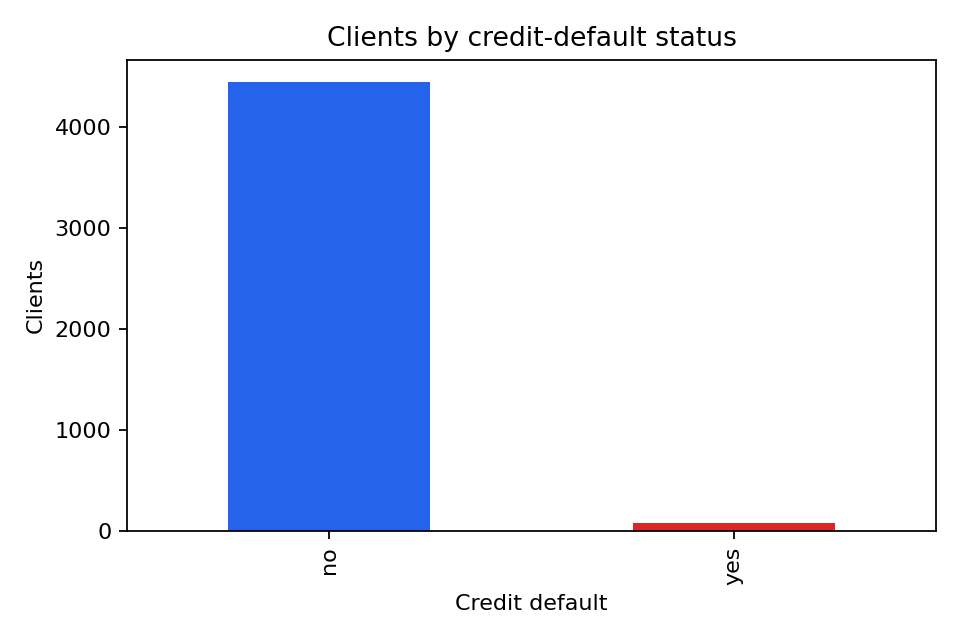

In [5]:
from IPython.display import Image, display

display(Image(filename=str(REPO_DIR / "outputs/job_counts.png")))
display(Image(filename=str(REPO_DIR / "outputs/default_counts.png")))

### Part 2 interpretation

The Spark job table shows retired clients with the highest mean balance, while management contributes the most rows among the top groups. The busiest month is May, whereas October has the highest subscription rate among months with enough contacts to report. Telephone's rate is slightly above cellular's but has a much smaller sample. The notebook shows the denominators beside rates so those differences are not over-interpreted.

# Part 3 — Spark ML prediction

The model predicts y with Logistic Regression. It indexes and one-hot encodes categorical fields, robust-scales numeric fields, and tunes the whole pipeline using three-fold cross-validation. The pipeline intentionally excludes duration because the value is recorded during/after a contact and could leak information into a pre-contact prediction. It preserves the pdays = -1 meaning with a separate prior-contact indicator.

In [6]:
run_project_script("src/spark/train_model.py", "--data", "data/bank.csv",
                   "--model", "outputs/model/bank_subscription_logistic")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/24 01:06:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/24 01:06:30 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/24 01:06:30 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


26/11/24 01:06:45 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


target counts
+---+-----+
|  y|count|
+---+-----+
| no| 4000|
|yes|  521|
+---+-----+

balance IQR diagnostics (RobustScaler is fit inside each CV fold)
balance_q1=71.00 balance_q3=1427.00 IQR_bounds=(-1963.00,3461.00) outside_iqr=530
pdays=-1 is a structural sentinel and is represented with a separate flag.
duration is excluded from features because it is observed during/after a call.
test_rows=859 best_cv_areaUnderPR=0.3411
test_areaUnderPR=0.3554
test_areaUnderROC=0.7592
test_accuracy=0.8906
test_f1=0.8423
test_weightedPrecision=0.8320
test_weightedRecall=0.8906
default_threshold_0.50 confusion_matrix (rows=actual, columns=predicted)
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|  764|
|  0.0|       1.0|    2|
|  1.0|       0.0|   92|
|  1.0|       1.0|    1|
+-----+----------+-----+

baseline_accuracy_all_no 0.8917
threshold_sensitivity (illustrative; threshold is not tuned on test data)
threshold=0.10 precision_yes=0.1648 recall_yes=0

### Part 3 interpretation

Use the printed test PR-AUC, ROC-AUC, F1, precision, recall, confusion matrix, and all-no baseline together. The positive class is only 11.52% of the data, so accuracy by itself can be misleading. Coefficients indicate association in this sample; they do not establish causes or justify decisions about individual customers.

# Part 4 — Structured Streaming, predictions, windows and watermark

The supplied file has no event timestamps. The chunk generator therefore adds deterministic synthetic event times and IDs, writes 120 historical rows as four files, and makes every seventeenth event 20 seconds late. The notebook consumes each file as a micro-batch, predicts with the fitted historical model in foreachBatch, updates mean balance and duration by job, and computes 10-second and one-minute windows with a one-minute watermark.

In [7]:
# The tracked sample contains four small chunks. Use a fresh temporary inbox
# and checkpoint directory so rerunning the notebook starts from the same events.
import tempfile
import shutil
from pathlib import Path

tmp_stream = Path(tempfile.mkdtemp(prefix="bank_stream_demo_"))
inbox = tmp_stream / "inbox"
inbox.mkdir()
for path in sorted((REPO_DIR / "data/stream_sample").glob("chunk-*.csv")):
    shutil.copy2(path, inbox / path.name)
print("chunks:", len(list(inbox.glob("chunk-*.csv"))))
print("sample rows:", sum(max(0, sum(1 for _ in open(p, encoding="utf-8")) - 1)
                           for p in inbox.glob("chunk-*.csv")))
print("late events are shifted 20 seconds; watermark threshold is 1 minute.")
run_project_script("src/streaming/run_streaming_demo.py",
                   "--model", "outputs/model/bank_subscription_logistic",
                   "--inbox", str(inbox),
                   "--checkpoint-dir", str(tmp_stream / "checkpoints"),
                   "--watermark", "1 minute", "--available-now")


chunks: 4
sample rows: 120
late events are shifted 20 seconds; watermark threshold is 1 minute.


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/24 01:06:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/24 01:06:52 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


26/11/24 01:06:52 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/11/24 01:06:52 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


10-second windows microbatch=0
1-minute windows microbatch=0


-------------------------------------------
Batch: 0
-------------------------------------------


... (7 outputs left out)

+--------+-------------------+-------------+-------+--------+---+-----------------------------------------+----------+
|event_id|event_time         |job          |balance|duration|y  |probability                              |prediction|
+--------+-------------------+-------------+-------+--------+---+-----------------------------------------+----------+
|0       |2025-05-01 09:00:00|unemployed   |1787.0 |79      |no |[0.8286935135343384,0.1713064864656616]  |0.0       |
|1       |2025-05-01 09:00:05|services     |4789.0 |220     |no |[0.9181235966057143,0.0818764033942857]  |0.0       |
|2       |2025-05-01 09:00:10|management   |1350.0 |185     |no |[0.7888502151893456,0.21114978481065438] |0.0       |
|3       |2025-05-01 09:00:15|management   |1476.0 |199     |no |[0.9533400453452502,0.04665995465474981] |0.0       |
|4       |2025-05-01 09:00:20|blue-collar  |0.0    |226     |no |[0.9504502523390426,0.04954974766095743] |0.0       |
|5       |2025-05-01 09:00:25|management   |747.

+--------+-------------------+------------+-------+--------+---+-----------------------------------------+----------+
|event_id|event_time         |job         |balance|duration|y  |probability                              |prediction|
+--------+-------------------+------------+-------+--------+---+-----------------------------------------+----------+
|60      |2025-05-01 09:05:00|blue-collar |-516.0 |554     |no |[0.9443028828545509,0.055697117145449115]|0.0       |
|61      |2025-05-01 09:05:05|retired     |415.0  |323     |no |[0.787522630457417,0.212477369542583]    |0.0       |
|62      |2025-05-01 09:05:10|management  |5887.0 |227     |no |[0.8424622271494385,0.15753777285056147] |0.0       |
|63      |2025-05-01 09:05:15|services    |1355.0 |134     |no |[0.8791617015956569,0.12083829840434313] |0.0       |
|64      |2025-05-01 09:05:20|admin.      |16873.0|223     |no |[0.7715904724298843,0.22840952757011568] |0.0       |
|65      |2025-05-01 09:05:25|blue-collar |203.0  |134  

+--------+-------------------+-------------+-------+--------+---+----------------------------------------+----------+
|event_id|event_time         |job          |balance|duration|y  |probability                             |prediction|
+--------+-------------------+-------------+-------+--------+---+----------------------------------------+----------+
|90      |2025-05-01 09:07:30|blue-collar  |111.0  |201     |no |[0.9004926160340343,0.0995073839659657] |0.0       |
|91      |2025-05-01 09:07:35|blue-collar  |455.0  |372     |no |[0.9516291195413596,0.04837088045864035]|0.0       |
|92      |2025-05-01 09:07:40|services     |-195.0 |391     |yes|[0.8867262428889924,0.11327375711100762]|0.0       |
|93      |2025-05-01 09:07:45|management   |3616.0 |165     |no |[0.8147463608091745,0.1852536391908255] |0.0       |
|94      |2025-05-01 09:07:50|blue-collar  |14093.0|231     |no |[0.8803755477940539,0.11962445220594609]|0.0       |
|95      |2025-05-01 09:07:55|unknown      |1567.0 |291 

+--------+-------------------+------------+-------+--------+---+-----------------------------------------+----------+
|event_id|event_time         |job         |balance|duration|y  |probability                              |prediction|
+--------+-------------------+------------+-------+--------+---+-----------------------------------------+----------+
|30      |2025-05-01 09:02:30|retired     |4189.0 |897     |yes|[0.8143377658134041,0.1856622341865959]  |0.0       |
|31      |2025-05-01 09:02:35|technician  |171.0  |81      |no |[0.8902139604121706,0.1097860395878294]  |0.0       |
|32      |2025-05-01 09:02:40|management  |42.0   |40      |no |[0.856357277570536,0.14364272242946396]  |0.0       |
|33      |2025-05-01 09:02:45|management  |2536.0 |958     |yes|[0.8794581833989774,0.12054181660102259] |0.0       |
|34      |2025-05-01 09:02:30|technician  |1235.0 |354     |yes|[0.8657390322448568,0.13426096775514318] |0.0       |
|35      |2025-05-01 09:02:55|admin.      |1811.0 |150  

### Part 4 trend analysis

Because the demo timestamps are spaced five seconds apart, a normal 10-second window contains about two rows and changes quickly. A one-minute window contains about twelve rows and smooths short-term swings in transaction count and average account balance. The intentionally late events are within the one-minute threshold. Spark uses the watermark to retain window state for bounded lateness and eventually clean old state; records later than the threshold are not guaranteed to update an aggregate.

For a paced replay in separate terminals, use src/streaming/run_streaming_demo.py with a persistent inbox and src/streaming/replay_chunks.py with --interval 2. The y field in the historical sample is included only to compare predictions against known outcomes.

# Part 5 — Data parallelism and resource management

The script repartitions rows by job, performs grouped aggregation, trains the same Logistic Regression pipeline on partitioned training data, records driver CPU/RSS snapshots, and schedules independent summaries in separate FAIR scheduler pools.

In [8]:
run_project_script("src/spark/data_parallelism.py", "--data", "data/bank.csv", "--partitions", "4")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/24 01:07:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/24 01:07:12 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/24 01:07:12 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


input_partitions 1
repartitioned_partitions 4
before_aggregations: python_driver_rss_mb=37.9, local_jvm_rss_mb=375.0, python_plus_jvm_cpu_pct_of_one_core=warming_up
average_balance_by_job (Spark shuffles and combines partition aggregates)
+-------------+------------------+
|job          |average_balance   |
+-------------+------------------+
|retired      |2319.191304347826 |
|housemaid    |2083.8035714285716|
|management   |1766.9287925696594|
|entrepreneur |1645.125          |
|student      |1543.8214285714287|
|unknown      |1501.7105263157894|
|self-employed|1392.4098360655737|
|technician   |1330.99609375     |
|admin.       |1226.73640167364  |
|services     |1103.9568345323742|
|unemployed   |1089.421875       |
|blue-collar  |1085.161733615222 |
+-------------+------------------+

top age bands by average-yearly-balance proxy among personal-loan clients
+--------+---------------------+---------------------------+--------------------------+
|age_band|personal_loan_clients|total_

### Part 5 interpretation

The dataset has a personal-loan indicator but no loan principal. Its balance is an average yearly balance per client. The top-five age-band output therefore ranks the sum of this balance measure among personal-loan holders as a labelled proxy. It does not estimate outstanding loan principal. Driver CPU and resident memory are local process readings, not cluster-wide monitoring. On this 4,521-row dataset, repartitioning demonstrates Spark's task model but cannot establish a performance gain over a cluster or even over a single process.

# Closing notes

The video script and reflection draft are in docs/. Before submission, rerun the notebook in Colab, read the metric values in Part 3, and personalize the reflection to match the experience and results. The supplied ZIP download path was not available, so the project uses bank.csv and the two available telecom notebooks as workflow references only.